# 第六周 · 新闻分类方法对比

本 Notebook 从真实执行结果重建图表。完整训练及评估入口见 README 和 train.py。

In [1]:
import json
from pathlib import Path
import numpy as np
from IPython.display import Markdown, display
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt

root=Path.cwd()
names=["majority","keyword","svm","logistic","bert_cls","bert_mean","qwen_zero","qwen_lora","bert_lora"]
results={n:json.loads((root/"results"/f"{n}.json").read_text(encoding="utf-8")) for n in names}
data={n:json.loads((root/"data"/f"{n}.json").read_text(encoding="utf-8")) for n in ("train","dev","test")}
labels=["故事","文化","娱乐","体育","财经","房产","汽车","教育","科技","军事","旅游","国际","证券","农业","电竞"]
sets={n:set(r["sentence"] for r in rows) for n,rows in data.items()}
assert not (sets["train"] & sets["dev"] or sets["train"] & sets["test"] or sets["dev"] & sets["test"])
assert all(r["truth"]==[x["label"] for x in data["test"]] for r in results.values())
print({n:len(rows) for n,rows in data.items()})
table=["| 方法 | Accuracy | Macro-F1 | 无效数 |","|---|---:|---:|---:|"]
for n,r in results.items():
    table.append(f"| {n} | {r['accuracy']:.2%} | {r['macro_f1']:.4f} | {r['invalid']} |")
display(Markdown("\n".join(table)))

{'train': 6000, 'dev': 1000, 'test': 1500}


| 方法 | Accuracy | Macro-F1 | 无效数 |
|---|---:|---:|---:|
| majority | 10.87% | 0.0131 | 0 |
| keyword | 13.67% | 0.0881 | 0 |
| svm | 49.40% | 0.4741 | 0 |
| logistic | 49.33% | 0.4704 | 0 |
| bert_cls | 46.20% | 0.4404 | 0 |
| bert_mean | 46.00% | 0.4288 | 0 |
| qwen_zero | 12.20% | 0.1647 | 1019 |
| qwen_lora | 52.33% | 0.4973 | 78 |
| bert_lora | 50.33% | 0.4822 | 0 |

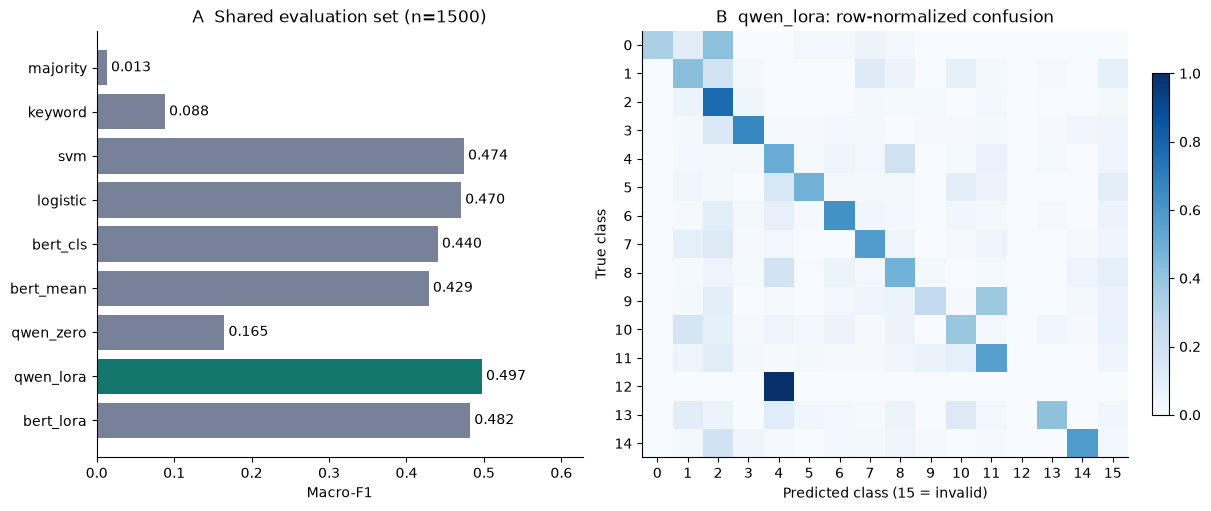

标签 ID {0: '故事', 1: '文化', 2: '娱乐', 3: '体育', 4: '财经', 5: '房产', 6: '汽车', 7: '教育', 8: '科技', 9: '军事', 10: '旅游', 11: '国际', 12: '证券', 13: '农业', 14: '电竞'}


In [2]:
best=max(names,key=lambda n:results[n]["macro_f1"])
with plt.rc_context({"font.size":10,"axes.spines.top":False,"axes.spines.right":False}):
    fig,axs=plt.subplots(1,2,figsize=(12,5),layout="constrained")
    ax=axs[0]
    values=[results[n]["macro_f1"] for n in names]
    bars=ax.barh(names,values,color=["#14776D" if n==best else "#778299" for n in names])
    ax.bar_label(bars,labels=[f"{v:.3f}" for v in values],padding=3)
    ax.set(xlabel="Macro-F1",xlim=(0,min(1,max(values)+.13)),title="A  Shared evaluation set (n=1500)")
    ax.invert_yaxis()
    cm=np.array(results[best]["confusion"])[:15,:]
    normal=cm / np.maximum(1,cm.sum(1,keepdims=True))
    image=axs[1].imshow(normal,cmap="Blues",vmin=0,vmax=1,aspect="auto")
    axs[1].set(title=f"B  {best}: row-normalized confusion",xlabel="Predicted class (15 = invalid)",
               ylabel="True class",xticks=range(16),yticks=range(15))
    fig.colorbar(image,ax=axs[1],shrink=.8)
    fig.savefig(root/"results/comparison.png",dpi=160,facecolor="white")
    plt.show()
print("标签 ID",dict(enumerate(labels)))

In [3]:
table=["| 类别 | 支持数 | SVM recall | BERT mean recall | Qwen LoRA recall |",
       "|---|---:|---:|---:|---:|"]
for label in labels:
    items=[results[n]["per_class"][label] for n in ("svm","bert_mean","qwen_lora")]
    table.append(f"| {label} | {items[0]['support']} | {items[0]['recall']:.2%} | "
                 f"{items[1]['recall']:.2%} | {items[2]['recall']:.2%} |")
display(Markdown("\n".join(table)))
for name in ("svm","logistic","bert_cls","bert_mean","qwen_lora"):
    print(name,results[name]["history"])
for name in ("qwen_zero","qwen_lora"):
    print(name,"预测分布",dict(zip(*np.unique(results[name]["predictions"],return_counts=True))))

| 类别 | 支持数 | SVM recall | BERT mean recall | Qwen LoRA recall |
|---|---:|---:|---:|---:|
| 故事 | 36.0 | 52.78% | 41.67% | 33.33% |
| 文化 | 97.0 | 35.05% | 34.02% | 42.27% |
| 娱乐 | 148.0 | 52.03% | 54.05% | 77.03% |
| 体育 | 117.0 | 61.54% | 60.68% | 66.67% |
| 财经 | 148.0 | 47.97% | 39.19% | 50.68% |
| 房产 | 52.0 | 69.23% | 63.46% | 48.08% |
| 汽车 | 125.0 | 56.80% | 51.20% | 62.40% |
| 教育 | 99.0 | 63.64% | 46.46% | 57.58% |
| 科技 | 163.0 | 39.88% | 38.04% | 47.85% |
| 军事 | 101.0 | 42.57% | 37.62% | 25.74% |
| 旅游 | 105.0 | 40.00% | 40.95% | 39.05% |
| 国际 | 125.0 | 41.60% | 44.00% | 56.00% |
| 证券 | 7.0 | 14.29% | 0.00% | 0.00% |
| 农业 | 78.0 | 51.28% | 43.59% | 41.03% |
| 电竞 | 99.0 | 55.56% | 58.59% | 58.59% |

svm [{'C': 0.5, 'dev_macro_f1': 0.4321577650144833}, {'C': 2.0, 'dev_macro_f1': 0.391928410331596}, {'C': 8.0, 'dev_macro_f1': 0.3823560539443293}]
logistic [{'C': 0.5, 'dev_macro_f1': 0.4548303011075119}, {'C': 2.0, 'dev_macro_f1': 0.4162907259372339}, {'C': 8.0, 'dev_macro_f1': 0.4147750322572389}]
bert_cls [{'C': 0.1, 'dev_macro_f1': 0.4904922903549575}, {'C': 1.0, 'dev_macro_f1': 0.4736066515332835}, {'C': 10.0, 'dev_macro_f1': 0.437808873061033}]
bert_mean [{'C': 0.1, 'dev_macro_f1': 0.4801167375754819}, {'C': 1.0, 'dev_macro_f1': 0.4262548164159973}, {'C': 10.0, 'dev_macro_f1': 0.41972140742856834}]
qwen_lora [{'epoch': 1, 'train_nll': 5.720371617635091, 'dev_nll': 4.921225112915039}, {'epoch': 2, 'train_nll': 4.817964450200399, 'dev_nll': 4.7924360771179195}, {'epoch': 3, 'train_nll': 4.736905837376913, 'dev_nll': 4.771737335205078}]
qwen_zero 预测分布 {np.int64(-1): np.int64(1019), np.int64(0): np.int64(88), np.int64(1): np.int64(15), np.int64(2): np.int64(85), np.int64(3): np.int6

In [4]:
print(f"{best} 的前 8 个错误例子")
shown=0
for row,pred in zip(data["test"],results[best]["predictions"]):
    if row["label"]!=pred:
        print(row["sentence"],"| true",labels[row["label"]],"| pred",labels[pred] if pred>=0 else "INVALID")
        shown+=1
        if shown==8: break
print("Qwen 零样本与 LoRA 的前 5 条输出")
for i,row in enumerate(data["test"][:5]):
    print(row["sentence"],"| true",labels[row["label"]])
    print("zero",results["qwen_zero"]["raw"][i])
    print("lora",results["qwen_lora"]["raw"][i])

qwen_lora 的前 8 个错误例子
为什么茂名流出人口数量在广东是最多？ | true 农业 | pred 财经
帮小舅子去接亲，见到新娘，我不动声色，悄悄把轮胎的气放光！ | true 故事 | pred 娱乐
滔滔岷江水 常伴睡梦中 | true 教育 | pred 旅游
文化美食节舌尖上的盛宴美众人 | true 旅游 | pred 文化
如何才能再看到老电影《桥》《瓦耳特保卫萨拉热窝》《老枪》等经典老片？ | true 文化 | pred 娱乐
心机女故意刁难灰姑娘，没想到总裁及时出现，心机女活活气跑 | true 电竞 | pred 娱乐
街头霸王当着泰森女人的面骂泰森是同性恋，结果被泰森一拳放倒！ | true 体育 | pred 娱乐
李克强考察丰田释放了什么信息？ | true 汽车 | pred 财经
Qwen 零样本与 LoRA 的前 5 条输出
为什么茂名流出人口数量在广东是最多？ | true 农业
zero {'text': '类别：故事\n\n标题：为什么茂名', 'stopped': False, 'new_tokens': 8}
lora {'text': '财经�IÊuheỊỊỊỊ', 'stopped': False, 'new_tokens': 8}
为什么有钱人在农村住？而农村人都在市区买房子？ | true 房产
zero {'text': '根据您提供的新闻标题，可以将', 'stopped': False, 'new_tokens': 8}
lora {'text': '房产 """",\n녔eligeARIANThtable녔elige', 'stopped': False, 'new_tokens': 8}
成都乡村里的小资情怀——崇州道明竹艺村 | true 旅游
zero {'text': '根据您提供的新闻标题，可以将', 'stopped': False, 'new_tokens': 8}
lora {'text': '旅游 """",\n녔elige:\'\'녔elige:\'\'', 'stopped': False, 'new_tokens': 8}
温暖的弦：感觉这是一部会哭瞎女主的戏！虐的虐死！甜的甜死！ | true 娱乐
zero {'text': '根据您提供的新闻标题，可以将', 's